# Week 5 — Additional Models

Goal: train **Decision Tree** and **Random Forest** regressors and compare their April test R² with the Week 4 **Linear Regression** baseline.

## 1. Setup

Reuse Week 4 imports and input discovery. Add the two tree estimators and helpers for independent preprocessing pipelines.


In [1]:
#importing libraries
import hashlib
import json
import platform
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

project_root = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "notebooks" / "02_preprocessing.ipynb").is_file()), None
)
if project_root is None:
    raise FileNotFoundError("Start the kernel in the project root or notebooks directory.")

# Week 3's executable export uses data/raw, despite some narrative paths saying data/.
# Prefer that location; support the documented alternate location if needed.
candidates = [project_root / folder / "cleaned_single_family_sales_with_splits.csv"
              for folder in ("data/raw", "data")]
input_path = next((p for p in candidates if p.is_file()), None)
if input_path is None:
    raise FileNotFoundError("Run the split export in 02_preprocessing.ipynb first.")
print("Input:", input_path.relative_to(project_root))

from sklearn.base import clone
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt


Input: data/cleaned_single_family_sales_with_splits.csv


## 2. Reuse the baseline data and preprocessing

The following cells preserve Week 4 split checks, feature selection, and train-only preprocessing. Scaling is unnecessary for trees, but retaining the same preprocessing makes this first comparison straightforward. Each model fits its own cloned preprocessor.


In [2]:
# features and target variable for model
NUMERIC_FEATURES = [
    "LivingArea", "LotSizeSquareFeet", "BedroomsTotal", "BathroomsTotalInteger",
    "GarageSpaces", "ParkingTotal", "Stories", "YearBuilt", "Latitude", "Longitude",
]
CATEGORICAL_FEATURES = ["City", "PostalCode"]
TARGET = "ClosePrice"

def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

# PostalCode kept as string for categorical feature
input_sha256 = sha256_file(input_path)
sales = pd.read_csv(input_path, dtype={"ListingKeyNumeric": "string", "PostalCode": "string"})
required = {TARGET, "CloseDate", "ListingKeyNumeric", "split", "selected_training_months"}
missing = required - set(sales.columns)
if missing:
    raise ValueError(f"Required columns missing: {sorted(missing)}")
if not sales["split"].isin(["train", "test", "outside_training_window"]).all():
    raise ValueError("Unexpected or missing split labels; review the Week 3 export.")
sales["CloseDate"] = pd.to_datetime(sales["CloseDate"], errors="raise")
sales[TARGET] = pd.to_numeric(sales[TARGET], errors="raise")
assert sales["CloseDate"].notna().all(), "Missing sale dates."
assert sales["ListingKeyNumeric"].notna().all() and sales["ListingKeyNumeric"].is_unique
assert (np.isfinite(sales[TARGET]) & sales[TARGET].gt(0)).all()

numeric_features = [c for c in NUMERIC_FEATURES if c in sales]
categorical_features = [c for c in CATEGORICAL_FEATURES if c in sales]
for c in numeric_features:
    sales[c] = pd.to_numeric(sales[c], errors="coerce").replace([np.inf, -np.inf], np.nan)
for c in categorical_features:
    sales[c] = sales[c].map(lambda v: str(v).strip() if pd.notna(v) and str(v).strip() else np.nan)

# spliting train/test data
train = sales.loc[sales["split"].eq("train")].copy()
test = sales.loc[sales["split"].eq("test")].copy()
assert len(train) > 0 and len(test) >= 2, "Need training data and at least two test rows."
assert train["CloseDate"].max() < test["CloseDate"].min(), "Split must be chronological."
months = sales["CloseDate"].dt.to_period("M")
test_month = months.max()
assert months.loc[test.index].eq(test_month).all()
assert sales.loc[months.eq(test_month), "split"].eq("test").all()
window_values = pd.to_numeric(sales["selected_training_months"], errors="raise").unique()
assert len(window_values) == 1 and np.isfinite(window_values[0])
window = int(window_values[0])
assert window > 0 and window == window_values[0]
expected_train = months.ge(test_month - window) & months.lt(test_month)
assert sales["split"].eq("train").equals(expected_train), "Split does not match selected window."
assert set(months.loc[train.index]) == set(pd.period_range(test_month - window, test_month - 1, freq="M"))
assert test[TARGET].nunique() > 1, "R² requires a nonconstant test target."

display(sales.groupby("split").agg(
    rows=(TARGET, "size"), first_sale=("CloseDate", "min"), last_sale=("CloseDate", "max")
))
print("Selected training window:", window, "months")


,rows,first_sale,last_sale
split,,,
outside_training_window,20150,2025-11-01,2025-12-31
test,12480,2026-04-01,2026-04-30
train,27974,2026-01-01,2026-03-31


Selected training window: 3 months


In [3]:
numeric_used = [c for c in numeric_features if train[c].notna().any()]
categorical_used = [c for c in categorical_features if train[c].notna().any()]
feature_columns = numeric_used + categorical_used
if not feature_columns:
    raise ValueError("No usable training predictors.")
print("Predictors:", feature_columns)
print("Entirely missing training features omitted:",
      sorted(set(numeric_features + categorical_features) - set(feature_columns)))

transformers = []
if numeric_used:
    transformers.append(("numeric", Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), numeric_used))
if categorical_used:
    transformers.append(("categorical", Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("encode", OneHotEncoder(handle_unknown="ignore", drop="first")),
    ]), categorical_used))

baseline_model = Pipeline([
    ("preprocess", ColumnTransformer(transformers)),
    ("regression", LinearRegression()),
])
X_train, y_train = train[feature_columns], train[TARGET]
X_test, y_test = test[feature_columns], test[TARGET]
baseline_model.fit(X_train, y_train)
print(f"Fitted Linear Regression on {len(train):,} sales.")


Predictors: ['LivingArea', 'LotSizeSquareFeet', 'BedroomsTotal', 'BathroomsTotalInteger', 'GarageSpaces', 'ParkingTotal', 'Stories', 'YearBuilt', 'Latitude', 'Longitude', 'City', 'PostalCode']
Entirely missing training features omitted: []
Fitted Linear Regression on 27,974 sales.


## 3. Fit the additional models

Start with fixed, reproducible settings. The unrestricted Decision Tree provides a useful check for overfitting. The Random Forest averages 100 trees to reduce variance. These are initial settings, not parameters selected using April scores.


In [ ]:
models = {
    "Linear Regression": baseline_model,
    "Decision Tree": Pipeline([
        ("preprocess", clone(baseline_model.named_steps["preprocess"])),
        ("regression", DecisionTreeRegressor(random_state=42)),
    ]),
    "Random Forest": Pipeline([
        ("preprocess", clone(baseline_model.named_steps["preprocess"])),
        ("regression", RandomForestRegressor(
            n_estimators=100, random_state=42, n_jobs=-1,
        )),
    ]),
}

# Linear Regression was fitted in Section 2.
for name in ["Decision Tree", "Random Forest"]:
    models[name].fit(X_train, y_train) 
    print(f"Fitted {name}.")


Fitted Decision Tree.
Fitted Random Forest.


## 4. Compare with the baseline

Test R² is the required metric; higher is better. MAE adds dollar-error context. A large train–test R² gap can suggest overfitting, although the change in time period also affects performance. Refit Linear Regression on the same inputs so all three scores come from this run.


In [5]:
comparison_rows = []
test_predictions_by_model = {}
for name, model in models.items():
    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)
    assert np.isfinite(test_prediction).all(), f"Nonfinite predictions: {name}"
    test_predictions_by_model[name] = test_prediction
    comparison_rows.append({
        "model": name,
        "train_r2": r2_score(y_train, train_prediction),
        "test_r2": r2_score(y_test, test_prediction),
        "test_mae_usd": mean_absolute_error(y_test, test_prediction),
    })

comparison = pd.DataFrame(comparison_rows).set_index("model")
comparison["r2_gap"] = comparison["train_r2"] - comparison["test_r2"]
comparison["test_r2_change_vs_baseline"] = (
    comparison["test_r2"] - comparison.loc["Linear Regression", "test_r2"]
)
display(comparison.style.format({
    "train_r2": "{:.4f}", "test_r2": "{:.4f}", "r2_gap": "{:.4f}",
    "test_r2_change_vs_baseline": "{:+.4f}", "test_mae_usd": "${:,.2f}",
}))

# Check whether the saved Week 4 score describes the identical data/features.
baseline_path = project_root / "results" / "03_baseline_results.json"
if baseline_path.is_file():
    saved_baseline = json.loads(baseline_path.read_text())
    same_inputs = (
        saved_baseline.get("input_sha256") == input_sha256
        and saved_baseline.get("numeric_features") == numeric_used
        and saved_baseline.get("categorical_features") == categorical_used
    )
    print("Saved Week 4 data and features match:", same_inputs)
    print("Saved Week 4 test R²:", saved_baseline.get("test_r2"))
    print("Use the same-run Linear Regression score above for this comparison.")


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,train_r2,test_r2,test_mae_usd,r2_gap,test_r2_change_vs_baseline
model,,,,,
Linear Regression,0.7376,0.6478,"$357,649.04",0.0898,+0.0000
Decision Tree,0.9981,0.5663,"$324,942.49",0.4318,-0.0814
Random Forest,0.9655,0.6881,"$242,223.32",0.2774,+0.0403


Saved Week 4 data and features match: True
Saved Week 4 test R²: 0.6477699349217355
Use the same-run Linear Regression score above for this comparison.


The unrestricted Decision Tree showed strong evidence of overfitting, achieving training R² of 0.9981 but test R² of only 0.5663, below the Linear Regression baseline. Random Forest reduced this gap and achieved the highest test R² (0.6881) and lowest MAE ($242,223). Its remaining train–test gap suggests overfitting is still a concern, although differences between the training months and April may also contribute.

## 5. Visualize and explain model behavior

Compare training and April test R² below. The findings document the initial run supplied during this walkthrough.


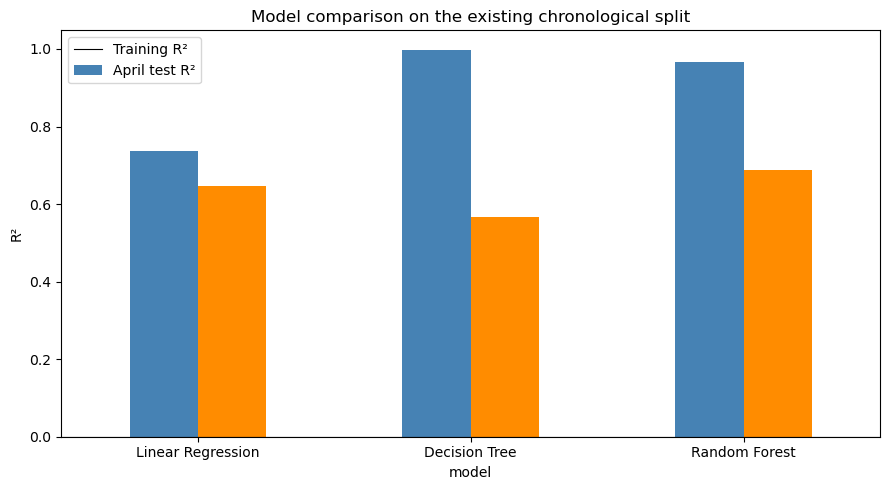

In [6]:
ax = comparison[["train_r2", "test_r2"]].plot.bar(
    figsize=(9, 5), rot=0, color=["steelblue", "darkorange"],
)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Model comparison on the existing chronological split", ylabel="R²")
ax.legend(["Training R²", "April test R²"])
plt.tight_layout()
plt.show()


### Models' strengths and weaknesses

| Model | Strengths | Weaknesses |
| --- | --- | --- |
| Linear Regression | Fast; interpretable coefficients; useful reference. | Assumes additive linear effects; can predict negative prices; correlated features can destabilize coefficients. |
| Decision Tree | Captures nonlinear relationships and feature interactions; individual splits can be inspected. | An unrestricted tree can memorize training data; sensitive to data changes; produces piecewise constant predictions. |
| Random Forest | Averages trees to reduce variance; captures nonlinear patterns and interactions. | More computation and memory; harder to explain; predictions do not extrapolate beyond training target values. |

### Findings from the initial run

| Model | Training R² | April test R² | Test MAE | Train–test R² gap |
| --- | ---: | ---: | ---: | ---: |
| Linear Regression | 0.7376 | 0.6478 | $357,649.04 | 0.0898 |
| Decision Tree | 0.9981 | 0.5663 | $324,942.49 | 0.4318 |
| Random Forest | 0.9655 | 0.6881 | $242,223.32 | 0.2774 |

**Baseline:** Linear Regression has the smallest train–test gap, but its April errors remain substantial. A small gap alone does not make it the most accurate model.

**Decision Tree:** The nearly perfect training R² and much lower test R² provide strong evidence of overfitting. Test R² decreased by 0.0814 relative to the baseline (using unrounded scores). Although its MAE improved, its worse R² indicates greater total squared error on the same test set. This is consistent with large misses receiving more weight under R²; residual analysis would show which homes contribute most.

**Random Forest:** Averaging 100 trees produced the best April results: test R² of 0.6881, an increase of 0.0403 over the baseline. MAE fell by $115,425.72, approximately 32.3%. The forest reduces the tree's generalization gap, but its own gap of 0.2774 still suggests overfitting. Differences between the training months and April can also contribute.

**Conclusion:** Random Forest is the strongest model in this initial April comparison on both required test R² and supporting MAE. All three models used the same 27,974 January–March training sales, 12,480 April test sales, and predictors. The saved Week 4 input and feature checks matched. These results describe one previously inspected holdout month and do not establish future performance.

**Next experiment:** First constrain tree complexity, then test whether removing one potentially overlapping feature improves earlier-month validation. Do not select settings or features by repeatedly comparing April scores.


## 6. Optional improvement experiment — earlier-month validation

Train on January–February and validate on March, using only the existing training partition. April is excluded from this experiment. This is an exploratory validation split: earlier work already used these months to select the training window.

Compare the original unrestricted models with three fixed complexity settings for each model. Select by validation R²; report MAE and the train–validation gap for context. Then, for the selected forest settings, compare all features with removal of **ParkingTotal**, which may overlap with **GarageSpaces**. This overlap is a hypothesis, not a measured finding. Keep the reduced set only if validation R² improves; removing one feature does not establish its overall importance.

Each experiment fits a new preprocessor on January–February only. The original models and April comparison remain available. No new April evaluation is included here; decide the final configuration from validation first.


In [7]:
validation_month = train["CloseDate"].dt.to_period("M").max()
experiment_train = train.loc[train["CloseDate"].dt.to_period("M").lt(validation_month)].copy()
experiment_valid = train.loc[train["CloseDate"].dt.to_period("M").eq(validation_month)].copy()
assert len(experiment_train) > 0 and len(experiment_valid) >= 2
assert experiment_train["CloseDate"].max() < experiment_valid["CloseDate"].min()
assert experiment_valid[TARGET].nunique() > 1
print("Experiment training:", experiment_train["CloseDate"].min().date(),
      "to", experiment_train["CloseDate"].max().date(), len(experiment_train), "sales")
print("Validation month:", validation_month, len(experiment_valid), "sales")

def evaluate_validation(estimator, columns):
    # Rebuild column selections so an omitted feature is actually removed.
    numeric = [c for c in columns if c in numeric_used and experiment_train[c].notna().any()]
    categorical = [c for c in columns if c in categorical_used and experiment_train[c].notna().any()]
    steps = []
    if numeric:
        steps.append(("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler()),
        ]), numeric))
    if categorical:
        steps.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encode", OneHotEncoder(handle_unknown="ignore", drop="first")),
        ]), categorical))
    candidate = Pipeline([
        ("preprocess", ColumnTransformer(steps)),
        ("regression", clone(estimator)),
    ])
    candidate.fit(experiment_train[columns], experiment_train[TARGET])
    training_pred = candidate.predict(experiment_train[columns])
    validation_pred = candidate.predict(experiment_valid[columns])
    assert np.isfinite(validation_pred).all()
    training_r2 = r2_score(experiment_train[TARGET], training_pred)
    validation_r2 = r2_score(experiment_valid[TARGET], validation_pred)
    return {
        "train_r2": training_r2, "validation_r2": validation_r2,
        "validation_mae_usd": mean_absolute_error(experiment_valid[TARGET], validation_pred),
        "r2_gap": training_r2 - validation_r2,
    }

experiment_candidates = {"Linear Regression reference": LinearRegression()}
for depth, leaf in [(None, 1), (None, 5), (15, 5), (10, 10)]:
    label = f"depth={depth}, leaf={leaf}"
    experiment_candidates[f"Decision Tree: {label}"] = DecisionTreeRegressor(
        max_depth=depth, min_samples_leaf=leaf, random_state=42,
    )
    experiment_candidates[f"Random Forest: {label}"] = RandomForestRegressor(
        n_estimators=100, max_depth=depth, min_samples_leaf=leaf,
        random_state=42, n_jobs=-1,
    )

validation_results = pd.DataFrame([
    {"configuration": name, **evaluate_validation(estimator, feature_columns)}
    for name, estimator in experiment_candidates.items()
]).set_index("configuration").sort_values("validation_r2", ascending=False)
display(validation_results.round(4))
print("These are March validation scores, not April test scores.")


Experiment training: 2026-01-01 to 2026-02-28 16423 sales
Validation month: 2026-03 11551 sales


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13

,train_r2,validation_r2,validation_mae_usd,r2_gap
configuration,,,,
"Random Forest: depth=None, leaf=1",0.9586,0.7337,249146.3152,0.2249
"Random Forest: depth=None, leaf=5",0.8274,0.7187,264821.5552,0.1087
"Random Forest: depth=15, leaf=5",0.8229,0.7159,273477.9416,0.1070
Linear Regression reference,0.7430,0.7072,345417.4715,0.0358
"Random Forest: depth=10, leaf=10",0.7460,0.6777,315980.9000,0.0683
"Decision Tree: depth=None, leaf=5",0.8268,0.6404,325089.7298,0.1864
"Decision Tree: depth=15, leaf=5",0.8179,0.6359,331603.0773,0.1820
"Decision Tree: depth=None, leaf=1",0.9966,0.6090,327706.3345,0.3876
"Decision Tree: depth=10, leaf=10",0.7248,0.5989,364084.5700,0.1259


These are March validation scores, not April test scores.


In [8]:
# Hold forest settings fixed while testing one feature removal.
forest_results = validation_results.loc[
    validation_results.index.str.startswith("Random Forest:")
]
best_forest_name = forest_results["validation_r2"].idxmax()
selected_forest = experiment_candidates[best_forest_name]
print("Selected forest configuration:", best_forest_name)

if "ParkingTotal" in feature_columns:
    reduced_columns = [c for c in feature_columns if c != "ParkingTotal"]
    full_metrics = forest_results.loc[best_forest_name].to_dict()
    reduced_metrics = evaluate_validation(selected_forest, reduced_columns)
    feature_experiment = pd.DataFrame([
        {"feature_set": "All baseline features", **full_metrics},
        {"feature_set": "Without ParkingTotal", **reduced_metrics},
    ]).set_index("feature_set")
    display(feature_experiment.round(4))
    delta = reduced_metrics["validation_r2"] - full_metrics["validation_r2"]
    print(f"Validation R² change after removal: {delta:+.4f}")
    print("Reduced features improve this validation split." if delta > 0
          else "Keep all features: removal did not improve validation R².")
    print("A small difference may be unstable; check additional earlier folds before a firm conclusion.")
else:
    print("ParkingTotal was not used; skip this feature-removal experiment.")


Selected forest configuration: Random Forest: depth=None, leaf=1


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,train_r2,validation_r2,validation_mae_usd,r2_gap
feature_set,,,,
All baseline features,0.9586,0.7337,249146.3152,0.2249
Without ParkingTotal,0.9586,0.7377,248104.1810,0.2209


Validation R² change after removal: +0.0040
Reduced features improve this validation split.
A small difference may be unstable; check additional earlier folds before a firm conclusion.


### Experiment findings — March validation

- **Decision Tree:** Increasing `min_samples_leaf` from 1 to 5, with no depth limit, improved validation R² from **0.6090 to 0.6404** and reduced the train–validation gap from **0.3876 to 0.1864**. Moderate regularization helped; stronger constraints did not improve further.
- **Random Forest:** The original unrestricted configuration (`n_estimators=100`, `max_depth=None`, `min_samples_leaf=1`, `random_state=42`) retained the highest validation R² (**0.7337**) and lowest validation MAE (**$249,146.32**) among the tested forest settings. Constraints reduced the gap but also reduced predictive performance. A smaller gap alone is not the selection objective.
- **Feature removal:** At the selected forest settings, removing `ParkingTotal` increased validation R² from **0.7337 to 0.7377** and reduced MAE to **$248,104.18**. The MAE improvement was approximately **$1,042 (0.4%)**. The gap changed only slightly, from **0.2249 to 0.2209**; this does not resolve overfitting.
- **Interpretation:** Keep the original forest settings and treat removal of `ParkingTotal` as provisional. A small improvement on one month does not establish that the feature is harmful or redundant. Check the same comparison on an earlier fold without searching for further settings.
- **Encoder warnings:** March contains cities or ZIP codes absent from January–February. The configured encoder represents these unseen values with all-zero indicators; these categories have no learned category-specific effect. The warnings do not indicate failed fitting, but highlight a limitation for unseen locations.

### 6.1 Repeat the fixed comparison: January → February

The next cell repeats the original-versus-leaf-5 complexity comparisons for both tree models and the unrestricted forest with versus without `ParkingTotal`. Settings are fixed from the March experiment; no April rows or scores are used. This fold reuses January training observations and February previously used for training, so agreement is supporting evidence rather than an independent final test. The saved repeat results and their interpretation appear below.


In [9]:
# Run after the Section 6 cells. Original March results remain unchanged.
months_in_train = train["CloseDate"].dt.to_period("M")
earliest_month = months_in_train.min()
early_train = train.loc[months_in_train.eq(earliest_month)].copy()
early_valid = train.loc[months_in_train.eq(earliest_month + 1)].copy()
assert len(early_train) > 0 and len(early_valid) >= 2
assert early_train["CloseDate"].max() < early_valid["CloseDate"].min()
assert early_valid[TARGET].nunique() > 1
print("Earlier fold:", earliest_month, "→", earliest_month + 1)
print("Training sales:", len(early_train), "Validation sales:", len(early_valid))

def evaluate_earlier_fold(estimator, columns, experiment_train, experiment_valid):
    # Rebuild column selections so an omitted feature is actually removed.
    numeric = [c for c in columns if c in numeric_used and experiment_train[c].notna().any()]
    categorical = [c for c in columns if c in categorical_used and experiment_train[c].notna().any()]
    steps = []
    if numeric:
        steps.append(("numeric", Pipeline([
            ("impute", SimpleImputer(strategy="median", add_indicator=True)),
            ("scale", StandardScaler()),
        ]), numeric))
    if categorical:
        steps.append(("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encode", OneHotEncoder(handle_unknown="ignore", drop="first")),
        ]), categorical))
    candidate = Pipeline([
        ("preprocess", ColumnTransformer(steps)),
        ("regression", clone(estimator)),
    ])
    candidate.fit(experiment_train[columns], experiment_train[TARGET])
    training_pred = candidate.predict(experiment_train[columns])
    validation_pred = candidate.predict(experiment_valid[columns])
    assert np.isfinite(validation_pred).all()
    training_r2 = r2_score(experiment_train[TARGET], training_pred)
    validation_r2 = r2_score(experiment_valid[TARGET], validation_pred)
    return {
        "train_r2": training_r2, "validation_r2": validation_r2,
        "validation_mae_usd": mean_absolute_error(experiment_valid[TARGET], validation_pred),
        "r2_gap": training_r2 - validation_r2,
    }

repeat_candidates = {
    "Decision Tree unrestricted": (DecisionTreeRegressor(random_state=42), feature_columns),
    "Decision Tree leaf=5": (DecisionTreeRegressor(min_samples_leaf=5, random_state=42), feature_columns),
    "Random Forest unrestricted": (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), feature_columns),
    "Random Forest leaf=5": (RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=42, n_jobs=-1), feature_columns),
}
if "ParkingTotal" in feature_columns:
    repeat_candidates["Random Forest without ParkingTotal"] = (
        RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
        [c for c in feature_columns if c != "ParkingTotal"],
    )
repeat_results = pd.DataFrame([
    {"configuration": name, **evaluate_earlier_fold(estimator, columns, early_train, early_valid)}
    for name, (estimator, columns) in repeat_candidates.items()
]).set_index("configuration")
display(repeat_results.style.format({
    "train_r2": "{:.4f}", "validation_r2": "{:.4f}",
    "validation_mae_usd": "${:,.2f}", "r2_gap": "{:.4f}",
}))

repeat_comparisons = [
    ("Tree: leaf=5 vs unrestricted", "Decision Tree leaf=5", "Decision Tree unrestricted"),
    ("Forest: leaf=5 vs unrestricted", "Random Forest leaf=5", "Random Forest unrestricted"),
]
if "ParkingTotal" in feature_columns:
    repeat_comparisons.append(("Forest: remove ParkingTotal", "Random Forest without ParkingTotal", "Random Forest unrestricted"))
repeat_deltas = pd.DataFrame([
    {"change": label,
     "validation_r2_change": repeat_results.loc[changed, "validation_r2"] - repeat_results.loc[reference, "validation_r2"],
     "validation_mae_change_usd": repeat_results.loc[changed, "validation_mae_usd"] - repeat_results.loc[reference, "validation_mae_usd"]}
    for label, changed, reference in repeat_comparisons
]).set_index("change")
display(repeat_deltas.round(4))
print("Positive R² change and negative MAE change favor the modification.")
print("Compare direction with March: tree leaf=5 helped; forest leaf=5 hurt; removing ParkingTotal helped slightly.")
print("If feature removal reverses direction across months, retain all features as the default; evidence is mixed.")


Earlier fold: 2026-01 → 2026-02
Training sales: 7473 Validation sales: 8950


/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/envs/myenv/lib/python3.13

,train_r2,validation_r2,validation_mae_usd,r2_gap
configuration,,,,
Decision Tree unrestricted,1.0000,0.4056,"$362,420.21",0.5944
Decision Tree leaf=5,0.8351,0.5339,"$343,033.79",0.3012
Random Forest unrestricted,0.9566,0.6543,"$271,711.26",0.3023
Random Forest leaf=5,0.8230,0.6441,"$290,192.91",0.1790
Random Forest without ParkingTotal,0.9572,0.6557,"$270,545.91",0.3016


,validation_r2_change,validation_mae_change_usd
change,,
Tree: leaf=5 vs unrestricted,0.1284,-19386.4190
Forest: leaf=5 vs unrestricted,-0.0102,18481.6552
Forest: remove ParkingTotal,0.0014,-1165.3448


Positive R² change and negative MAE change favor the modification.
Compare direction with March: tree leaf=5 helped; forest leaf=5 hurt; removing ParkingTotal helped slightly.
If feature removal reverses direction across months, retain all features as the default; evidence is mixed.


### Earlier-fold findings — January → February

This repeat trained on **7,473 January sales** and validated on **8,950 February sales**. All three changes had the same direction as the March experiment.

| Fixed change | February validation R² change | February MAE change | March validation R² change | March MAE change |
| --- | ---: | ---: | ---: | ---: |
| Decision Tree: leaf=5 vs unrestricted | +0.1284 | −$19,386.42 | +0.0314 | −$2,616.60 |
| Random Forest: leaf=5 vs unrestricted | −0.0102 | +$18,481.66 | −0.0150 | +$15,675.24 |
| Random Forest: remove ParkingTotal | +0.0014 | −$1,165.34 | +0.0040 | −$1,042.13 |

Changes use underlying scores where available; displayed rounded scores can differ slightly when subtracted. Positive R² changes and negative MAE changes favor the modification.

**Tree complexity:** Setting `min_samples_leaf=5` improved Decision Tree validation performance in both periods. On February, R² increased from 0.4056 to 0.5339 and the gap shrank from 0.5944 to 0.3012. The constrained tree still scored below the unrestricted forest.

**Forest complexity:** Increasing the forest's minimum leaf size reduced the gap but worsened R² and MAE in both periods. Retain the unrestricted forest settings among those tested.

**Feature removal:** Removing ParkingTotal improved both metrics in both periods. February R² increased from 0.6543 to 0.6557 and MAE decreased from $271,711.26 to $270,545.91. This supports using the reduced feature set as the provisional forest configuration for subsequent work. The gain is small and does not establish statistical significance, prove redundancy, or resolve overfitting.

**Decision:** Carry forward a 100-tree Random Forest with `max_depth=None`, `min_samples_leaf=1`, `random_state=42`, excluding ParkingTotal as a provisional candidate. Keep the original full-feature April results as the recorded Week 5 comparison; this candidate has not been refitted on January–March or evaluated on April here. Both validation folds reuse historical data, so agreement supports consistency rather than an independent final performance claim. Future feature engineering should compare against a clearly specified reference feature set.



## Final findings and rationale

### Why we explored restrictions and feature removal

The initial unrestricted Decision Tree nearly memorized the training data (R² = 0.9981) but scored only 0.5663 on April. The Random Forest performed better on April (R² = 0.6881) but also had a substantial training–test gap. These gaps motivated checking whether simpler trees would generalize better. They did not, by themselves, prove that the models used too many features; differences between months can also contribute.

We tested `max_depth` to limit successive splits and `min_samples_leaf` to require more observations in each terminal leaf. Both restrict how specific a tree can become. We separately removed ParkingTotal because it could overlap with GarageSpaces. This was a hypothesis tested with validation, not an assumption that parking information was unhelpful. Holding forest settings fixed during removal helped isolate the feature-set change.

### What the experiments established

- **Initial April comparison:** Random Forest outperformed Linear Regression and Decision Tree, with test R² **0.6881** and MAE **$242,223.32**. Relative to Linear Regression, R² increased by **0.0403** and MAE decreased by approximately **32.3%**.
- **Decision Tree restrictions:** A minimum leaf size of 5 improved validation R² in both February and March. This supports moderate complexity control for the single tree, although it remained below the unrestricted forest on these folds.
- **Random Forest restrictions:** The tested restrictions reduced train–validation gaps but worsened validation R² and MAE. We therefore did not select a restriction simply to make the gap smaller.
- **Feature removal:** Excluding ParkingTotal slightly improved both R² and MAE in both validation periods. This supports carrying the smaller feature set forward provisionally; it does not prove redundancy or statistical significance.

### Final decision and completion status

The original, full-feature Random Forest remains the model with the best measured April performance in the initial comparison. For subsequent experiments, the provisional candidate is a Random Forest with **100 trees**, **no depth limit**, **minimum leaf size 1**, **random_state=42**, and **ParkingTotal excluded**.

The reduced-feature candidate was evaluated on earlier validation folds only. It has not been refitted on all January–March sales or assigned an April test score here; do not attribute the original model's April score to it. Any later refit or evaluation should be recorded as a separate experiment. April was previously inspected, so an untouched future holdout would be needed for a stronger final performance claim.
